<a href="https://colab.research.google.com/github/MhiyaJ/My-GIS-Stuff/blob/main/CCHSDistrict(together).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **DO NOT RUN ALL!! WORK FROM 'STOP'**

IMPORTING PROGRAMS

Source: theaok.github.io/gisPy/, map.ipynb, Retrieved October 20, 2026

In [155]:
%%capture
!pip install adjustText

import os, zipfile
import pandas as pd #
import matplotlib.pyplot as plt

import geopandas as gpd

import mapclassify

import seaborn as sns

from matplotlib.patches import Ellipse

from matplotlib.patheffects import withStroke

from adjustText import adjust_text

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files

from geopandas.tools import geocode

from google.colab.data_table import DataTable
DataTable.max_columns = 250

gpd.__version__

SECONDARY SCHOOL DISTRICT

There are 3 Regional high schools in Camden County; Eastern, Sterling and Black Horse Pike

In [156]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Secondary_-5568767075062576326.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njrhs = gpd.read_file('School_Districts_Secondary.shp')

Municipalities.cpg		School_Districts_Secondary.prj
Municipalities.dbf		School_Districts_Secondary.shp
Municipalities.prj		School_Districts_Secondary.shp.xml
Municipalities.shp		School_Districts_Secondary.shx
Municipalities.shx		School_Districts_Unified.cpg
Municipalities.xml		School_Districts_Unified.dbf
Muni.zip			School_Districts_Unified.prj
njhighschools.zip		School_Districts_Unified.shp
sample_data			School_Districts_Unified.shp.xml
School_Districts_Secondary.cpg	School_Districts_Unified.shx
School_Districts_Secondary.dbf


In [157]:
njrhs.head(3)

,NJDOE_ID_S,DIST_NAME,SCSDLEA,SD_TYPE,GEOID,geometry
0,03-4300,Ramapo Indian Hills Regional High School District,13560,S,3413560,"POLYGON ((581460.48 800555.65, 581472.241 8005..."
1,19-3660,North Hunterdon-Voorhees Regional High School ...,11610,S,3411610,"POLYGON ((391770.815 705704.676, 392388.938 70..."
2,31-3980,Passaic County Manchester Regional High School...,12600,S,3412600,"POLYGON ((584057.82 765144.57, 584036.38 76509..."


In [158]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njrhs["NJDOE_ID_S"] = njrhs["NJDOE_ID_S"].astype(str)
njrhs[["CountyCode", "DistrictCode"]] = njrhs["NJDOE_ID_S"].str.extract(r"(\d{2}).*(\d{4})")

In [159]:
#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njrhs2 = njrhs[njrhs['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID', 'geometry']]
njrhs2['DistrictCode']=njrhs2.DistrictCode.str.strip()

njrhs2

,DistrictCode,CountyCode,DIST_NAME,GEOID,geometry
20,5035,07,Sterling Regional School District,3402880,"POLYGON ((342322.53 375467.11, 345610.5 373541..."
40,0390,07,Black Horse Pike Regional School District,3401770,"POLYGON ((322014.45 380972.53, 321992.84 38092..."
42,1255,07,Eastern Camden County Regional School District,3404380,"MULTIPOLYGON (((367503.372 354073.834, 370576...."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

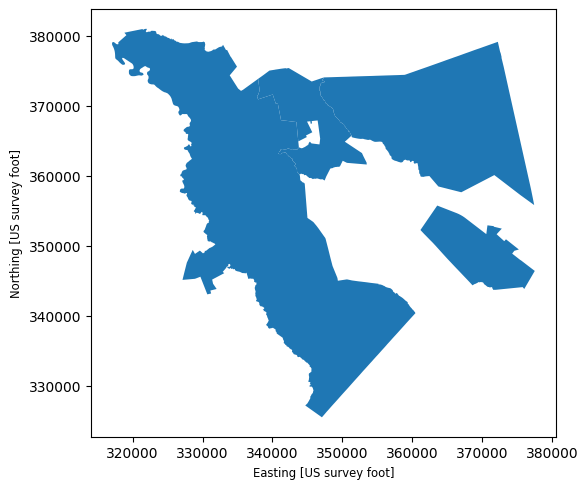

In [160]:
njrhs2.plot(figsize=(6,8))

UNIFIED SCHOOL DISTIRCTS

High schools that operate within their own district.  Some schools may be K - 12.

In [161]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Unified_7341673536716239500.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njsch = gpd.read_file('School_Districts_Unified.shp')

Municipalities.cpg		School_Districts_Secondary.prj
Municipalities.dbf		School_Districts_Secondary.shp
Municipalities.prj		School_Districts_Secondary.shp.xml
Municipalities.shp		School_Districts_Secondary.shx
Municipalities.shx		School_Districts_Unified.cpg
Municipalities.xml		School_Districts_Unified.dbf
Muni.zip			School_Districts_Unified.prj
njhighschools.zip		School_Districts_Unified.shp
sample_data			School_Districts_Unified.shp.xml
School_Districts_Secondary.cpg	School_Districts_Unified.shx
School_Districts_Secondary.dbf


In [162]:
njsch.columns

Index(['NJDOE_ID_U', 'DIST_NAME', 'UNSDLEA', 'SD_TYPE', 'GEOID', 'geometry'], dtype='object')

In [163]:
njsch.head(5)

,NJDOE_ID_U,DIST_NAME,UNSDLEA,SD_TYPE,GEOID,geometry
0,05-5805,Willingboro Public School District,18000,U,3418000,"POLYGON ((386370.414 440959.026, 389173.931 44..."
1,23-4920,South River Public School District,15390,U,3415390,"POLYGON ((524300.577 593657.109, 524249.62 593..."
2,23-1170,East Brunswick Township School District,04110,U,3404110,"POLYGON ((526398.44 599176.69, 526588.81 59853..."
3,23-3290,Monroe Township School District,10500,U,3410500,"POLYGON ((520841.5 564988.81, 520860.72 564987..."
4,03-1130,Dumont Public School District,03990,U,3403990,"POLYGON ((636857.058 772962.29, 636946.462 772..."


In [164]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njsch["NJDOE_ID_U"] = njsch["NJDOE_ID_U"].astype(str)
njsch[["CountyCode", "DistrictCode"]] = njsch["NJDOE_ID_U"].str.extract(r"(\d{2}).*(\d{4})")

In [165]:
#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njsch2=njsch[njsch['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID','geometry']]
njsch2['DistrictCode']=njsch2.DistrictCode.str.strip()

njsch2

,DistrictCode,CountyCode,DIST_NAME,GEOID,geometry
34,5820,07,Winslow Township School District,3418060,"POLYGON ((368609.977 344389.586, 368631.27 344..."
41,0150,07,Audubon Public School District,3401050,"POLYGON ((333599.519 389532.256, 334908.018 38..."
43,0940,07,Collingswood Public School District,3403420,"POLYGON ((329936.77 398206.61, 330020.49 39819..."
50,1880,07,Haddon Heights School District,3406330,"POLYGON ((338431.442 383843.61, 338435.82 3836..."
51,2130,07,Hi Nella,3407080,"POLYGON ((346458.121 367972.644, 346568.817 36..."
52,3770,07,Oaklyn Public School District,3411940,"POLYGON ((331980.807 391389.812, 331778.88 391..."
53,0800,07,Cherry Hill School District,3403000,"POLYGON ((347458.19 406942.14, 347464.79 40692..."
54,1900,07,Haddonfield School District,3406390,"POLYGON ((341402.77 394798.54, 341480.9 394783..."
58,4110,07,Pine Hill School District,3412990,"POLYGON ((351592.589 354425.759, 351577.79 351..."
59,1890,07,Haddon Township School District,3406360,"MULTIPOLYGON (((325315.69 389559.475, 325405.0..."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

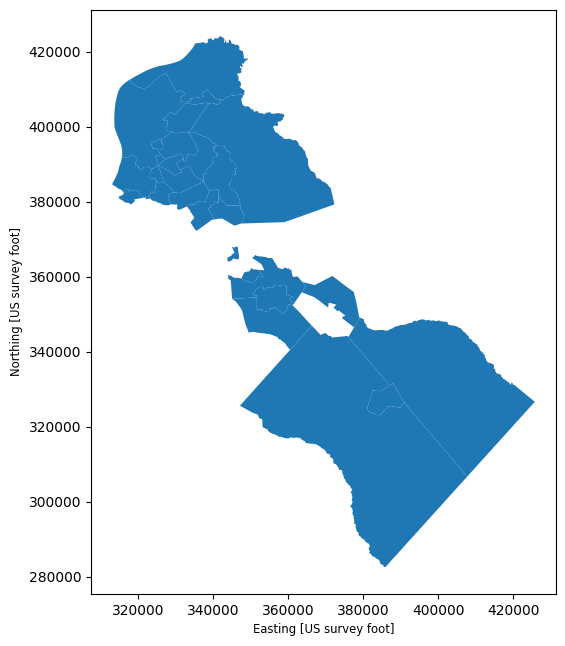

In [166]:
njsch2.plot(figsize=(6,8))

CAMDEN COUNTY SCHOOL DISTRICTS

The spreadsheets of Secondary and Unified School Districts were combined to create one map.

In [167]:
#Googled: How to combine onto 1 spreadsheet
#Add optional column to keep track where rows come from
njsch2['School Type']='Unified'
njrhs2['School Type']='Secondary'

#Stack them into one single geodataframe
cchs=pd.concat([njsch2, njrhs2], ignore_index=True)

#convert back to geodataframe to preserve map plotting capabilities
cchs=gpd.GeoDataFrame(cchs,geometry='geometry')


In [168]:
#Renamed columns, fix mispelling and remove words
cchs.rename(columns={'DIST_NAME' : 'District'}, inplace=True)
cchs['District'] = cchs['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
cchs['District'] = cchs['District'].str.replace("LAWNSIDE SCHOOL DISTRIC", "LAWNSIDE SCHOOL DISTRICT")
cchs["District"] = cchs["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
cchs["District"] = cchs["District"].str.replace(" REGIONAL", "")
cchs["District"] = cchs["District"].str.replace(" SCHOOL DISTRICT", "")
cchs["District"] = cchs["District"].str.replace(" BOARD OF EDUCATION", "")

cchs

,DistrictCode,CountyCode,District,GEOID,geometry,School Type
0,5820,07,Winslow Township School District,3418060,"POLYGON ((368609.977 344389.586, 368631.27 344...",Unified
1,0150,07,Audubon Public School District,3401050,"POLYGON ((333599.519 389532.256, 334908.018 38...",Unified
2,0940,07,Collingswood Public School District,3403420,"POLYGON ((329936.77 398206.61, 330020.49 39819...",Unified
3,1880,07,Haddon Heights School District,3406330,"POLYGON ((338431.442 383843.61, 338435.82 3836...",Unified
4,2130,07,Hi Nella,3407080,"POLYGON ((346458.121 367972.644, 346568.817 36...",Unified
5,3770,07,Oaklyn Public School District,3411940,"POLYGON ((331980.807 391389.812, 331778.88 391...",Unified
6,0800,07,Cherry Hill School District,3403000,"POLYGON ((347458.19 406942.14, 347464.79 40692...",Unified
7,1900,07,Haddonfield School District,3406390,"POLYGON ((341402.77 394798.54, 341480.9 394783...",Unified
8,4110,07,Pine Hill School District,3412990,"POLYGON ((351592.589 354425.759, 351577.79 351...",Unified
9,1890,07,Haddon Township School District,3406360,"MULTIPOLYGON (((325315.69 389559.475, 325405.0...",Unified


In [169]:
cchs.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   DistrictCode  28 non-null     object  
 1   CountyCode    28 non-null     object  
 2   District      28 non-null     object  
 3   GEOID         28 non-null     object  
 4   geometry      28 non-null     geometry
 5   School Type   28 non-null     object  
dtypes: geometry(1), object(5)
memory usage: 1.4+ KB


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

(np.float64(308456.66427294584),
 np.float64(430201.67503440706),
 np.float64(276823.57176200213),
 np.float64(429700.2905748793))

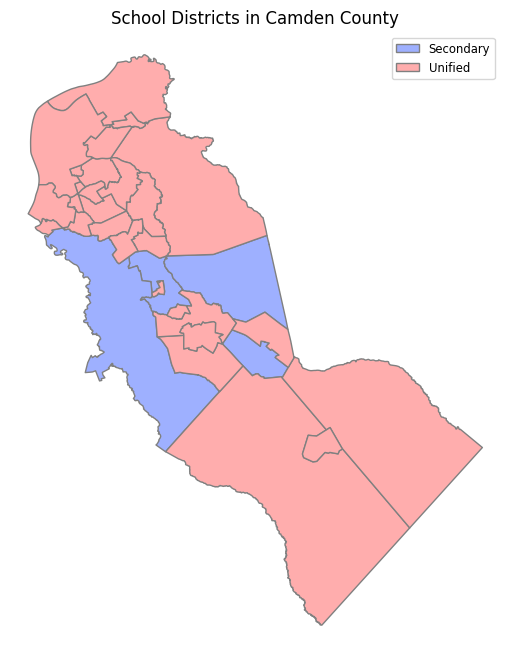

In [175]:
fig, ax = plt.subplots(1, figsize=(8,8))
cchs.plot(ax=ax,column='School Type',legend=True,cmap='berlin',
         edgecolor='grey',linewidth=1,legend_kwds={
        'loc':'upper right','title_fontsize':'medium','fontsize':'small','markerscale':1.4})

ax.title.set_text("School Districts in Camden County")
ax.set_xticks([])
ax.set_yticks([])
ax.margins(0.04)
ax.axis("off")


OVERLAY MUNICPAL SHAPEFILE

In [171]:
!wget -q -O Muni.zip  https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Municipalities.zip
zip_ref = zipfile.ZipFile('Muni.zip', 'r');zip_ref.extractall(); zip_ref.close()

Muni = gpd.read_file('Municipalities.shp')

In [172]:
Muni.columns

Index(['FID', 'COUSUBNS', 'GEOID', 'NAMELSAD', 'CLASSFP', 'FUNCSTAT', 'ALAND',
       'AWATER', 'INTPTLAT', 'INTPTLON', 'Shape_Leng', 'GEOCODE', 'GlobalID',
       'Shape__Are', 'Shape__Len', 'geometry'],
      dtype='object')

In [173]:
Muni.head()

,FID,COUSUBNS,GEOID,NAMELSAD,CLASSFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,GEOCODE,GlobalID,Shape__Are,Shape__Len,geometry
0,1,00885144,3400702200,Audubon borough,C5,F,3838781,35535,+39.8901277,-75.0723825,9407.757950,3400702200,81d661c6-35a7-42ed-8afd-5f35d0b0e807,3.871214e+06,9407.757866,"POLYGON ((495599.23 4415536.249, 495508.749 44..."
1,2,00885145,3400702230,Audubon Park borough,C5,F,389606,46935,+39.8968373,-75.0888190,2734.677596,3400702230,f8ccbea8-76dd-44e7-992b-e367d22e31a1,4.361934e+05,2734.677499,"POLYGON ((492866.221 4416337.872, 492855.687 4..."
2,3,00885149,3400703250,Barrington borough,C5,F,4095340,0,+39.8689349,-75.0513618,11456.984021,3400703250,9e9086b1-16e4-429f-b5c4-d967de1dbd82,4.092067e+06,11456.984073,"POLYGON ((496819.374 4414558.505, 496827.878 4..."
3,4,00885154,3400704750,Bellmawr borough,C5,F,7729295,315734,+39.8663560,-75.0946695,18085.471872,3400704750,bdd07346-3ee8-471e-befd-b8b9e16eb0a9,8.038608e+06,18085.472003,"POLYGON ((492951.896 4413667.751, 492968.147 4..."
4,5,00885158,3400705440,Berlin borough,C5,F,9307767,35573,+39.7920594,-74.9369855,14823.777678,3400705440,032f4608-e579-4343-a5e1-7d3778ce56c5,9.335884e+06,14823.777540,"POLYGON ((507881.319 4403761.193, 507873.371 4..."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

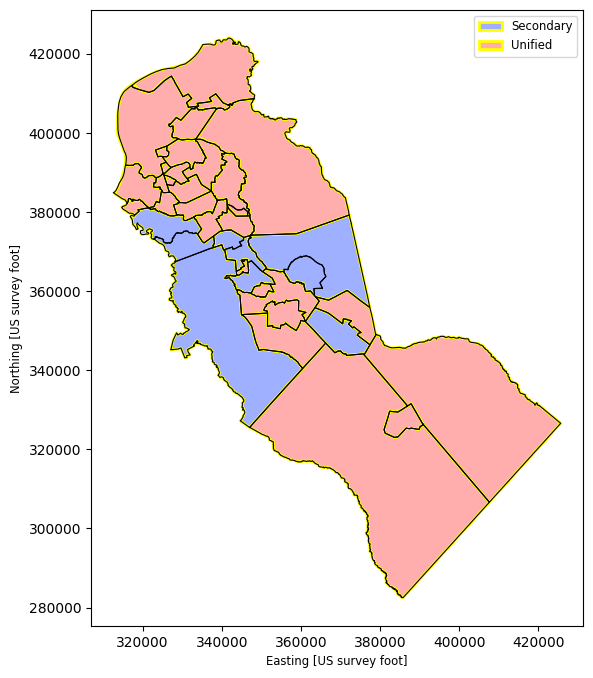

In [182]:
fig, ax = plt.subplots(1, figsize=(8,8))

# Plot school districts
cchs.plot(ax=ax, column='School Type', legend=True, cmap='berlin',
          edgecolor='yellow', linewidth=2, legend_kwds={
          'loc':'upper right', 'title_fontsize':'medium', 'fontsize':'small', 'markerscale':2})

# Attempted to overlay with Muni.plot (ax=ax, edgecolor='black', linewidth=.8, facecolor="none") but an error occurred
#Requested to explain error, results turned to CRS
#Ensure Muni is in the same CRS as cchs so they overlay correctly
njMuni = Muni.to_crs(cchs.crs)

# Overlay municipal boundaries
njMuni.plot(ax=ax, edgecolor='black', linewidth=.8, facecolor="none")

### **STOP STOP STOP STOP**

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

([Text(368454.9635744294, 315860.3455206534, 'WINSLOW TOWNSHIP'),
  Text(343874.83265551936, 384396.203449833, 'AUDUBON'),
  Text(344357.66239836736, 396487.7347666257, 'COLLINGSWOOD'),
  Text(346851.5872387507, 380577.0366691216, 'HADDON HEIGHTS'),
  Text(339497.39085617266, 366211.8479671228, 'HI NELLA'),
  Text(323998.76338932174, 391121.088263341, 'OAKLYN'),
  Text(367327.69346627564, 390721.2440918298, 'CHERRY HILL'),
  Text(351229.7154798202, 387866.27718965, 'HADDONFIELD'),
  Text(362842.3008766729, 347155.53917157836, 'PINE HILL'),
  Text(344626.2018841959, 393553.0453053487, 'HADDON TOWNSHIP'),
  Text(363635.1456526994, 357720.75101462344, 'LINDENWOLD'),
  Text(350752.98973594175, 376212.81011298264, 'LAWNSIDE'),
  Text(416175.24111812434, 332137.8608400872, 'WATERFORD TOWNSHIP'),
  Text(330496.9021646114, 376643.05585209915, 'BARRINGTON'),
  Text(323263.5251162939, 397949.7702161956, 'WOODLYNNE'),
  Text(340715.6329702324, 359017.99513340986, 'LAUREL SPRINGS'),
  Text(348960.

[]

[]

(np.float64(308456.66427294584),
 np.float64(430201.67503440706),
 np.float64(276823.57176200213),
 np.float64(429700.2905748793))

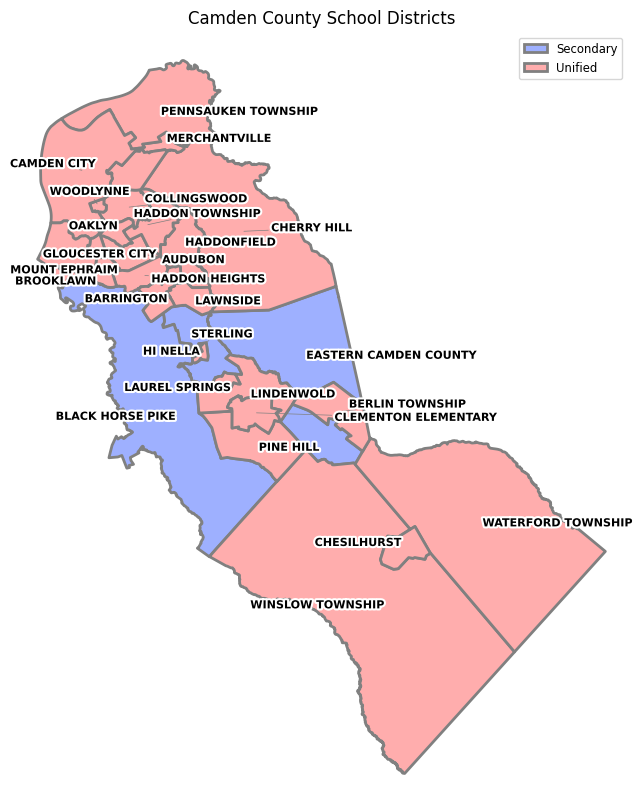

In [ ]:
fig, ax = plt.subplots(1, figsize=(10,10))
cchs.plot(ax=ax,column='type',legend=True,cmap='berlin',
         edgecolor='grey',linewidth=2,legend_kwds={
        'loc':'upper right','title_fontsize':'medium','fontsize':'small','markerscale':1.4})

# Prompted Gemini to fix label overlap
texts = []
for x, y, label in zip(cchs.geometry.centroid.x, cchs.geometry.centroid.y, cchs.District):
    t = ax.text(x, y, label, fontsize=8, color='black', fontweight='bold',
                horizontalalignment='center', verticalalignment='center')
    t.set_path_effects([withStroke(linewidth=3, foreground='white')])
    texts.append(t)

# Automatically resolve all overlaps
adjust_text(texts, arrowprops=dict(arrowstyle="-", color='gray', lw=0.5))

ax.title.set_text("Camden County School Districts")
ax.set_xticks([])
ax.set_yticks([])
ax.margins(0.04)
ax.axis("off")
plt.show()

In [ ]:
PrgXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/After%20School%20Programs.2.xlsx')

In [ ]:
PrgXls.head()

,After School Programs,Address,Unnamed: 2
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health


In [ ]:
#Rename columns and separated program types
PrgXls = PrgXls.rename(columns={'Unnamed: 2': 'Prog Type'})
PrgXls

,After School Programs,Address,Prog Type
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health
5,Collingswood Early Childhood Center,"201 Dayton Ave., Collingswood, NJ 08108",Health
6,Parkview Preschool,"700 W. Browning Rd., Collingswood, NJ 08107",Health
7,Oaklyn Public School,"136 Kendall Blvd., Oaklyn, NJ 08107",Health
8,"After-School All-Stars, Copewood Campus","1650 Copewood St., Camden, NJ 08103",General
9,"After-School All-Stars, Mt. Ephraim Campus","1575 Mt. Ephraim Ave., Camden, NJ 08104",General


In [ ]:
#Prompted Gemini to fix error due to length of after school program list

# Combine 'Address' and 'City' into a single string for better geocoding accuracy
full_addresses = PrgXls['Address'].astype(str) + ", New Jersey"

# Geocode using 'arcgis' provider to avoid Nominatim's strict 429 rate limiting
geo = geocode(full_addresses, provider='arcgis', timeout=10)
geo.head(3)

,geometry,address
0,POINT (-75.06635 39.9196),"265 Lincoln Ave, Collingswood, New Jersey, 08108"
1,POINT (-75.08938 39.91174),"400 Comly Ave, Oaklyn, New Jersey, 08107"
2,POINT (-75.07578 39.91817),"480 Haddon Ave, Collingswood, New Jersey, 08108"


In [ ]:
#PrgXls=gpd.GeoDataFrame(cchs,geometry='geometry'), didn't run therefore prompted Gemini to explain and fix error
# Assign the geocoded geometry to the main DataFrame
PrgXls['geometry'] = geo['geometry']

# Convert to a GeoDataFrame using the new geometry column
PrgXls = gpd.GeoDataFrame(PrgXls, geometry='geometry')

# End of Gemini assistance

#Strip to categorize
PrgFsc = PrgXls[PrgXls['Prog Type'].str.strip() == 'Family Success Center']
PrgCom = PrgXls[PrgXls['Prog Type'].str.strip() == 'Community Center']
PrgGen = PrgXls[PrgXls['Prog Type'].str.strip() == 'General']
PrgHea = PrgXls[PrgXls['Prog Type'].str.strip() == 'Health']

PrgXls.head(3)

,After School Programs,Address,Prog Type,geometry
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health,POINT (-75.06635 39.9196)
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health,POINT (-75.08938 39.91174)
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health,POINT (-75.07578 39.91817)


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

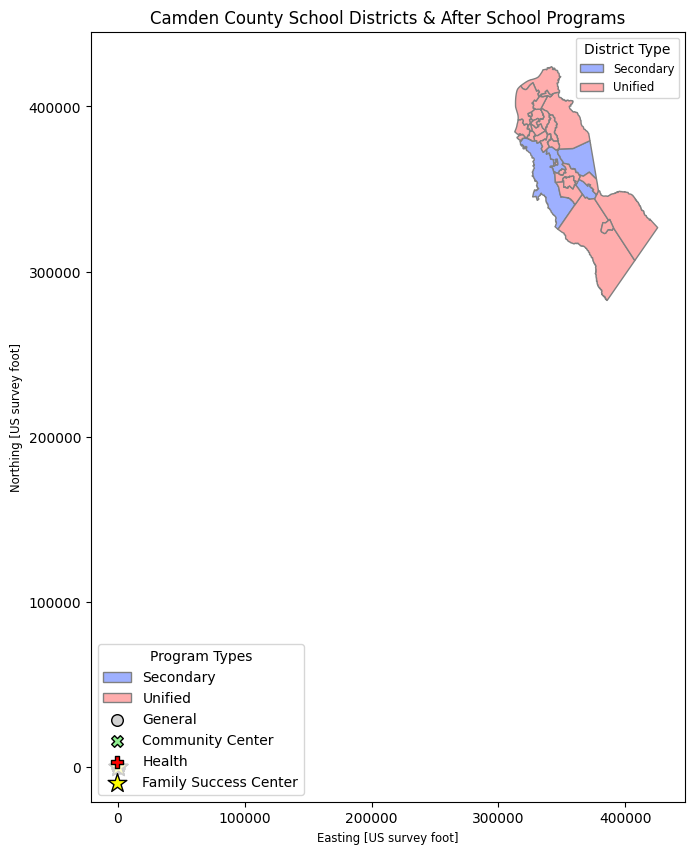

In [ ]:
# Original run
fig, ax = plt.subplots(1, figsize=(10,10))

cchs.plot(ax=ax, column='type', legend=True, cmap='berlin',
          edgecolor='grey', linewidth=1, legend_kwds={
          'loc':'upper right', 'title_fontsize':'medium', 'fontsize':'small', 'markerscale':1.4,'title':'District Type'})

# Prompted Gemini to create two legends
# Save the first legend (District Type) to prevent it from being overwritten
District_legend = ax.get_legend()

PrgGen.plot(ax=ax, marker='o', color='lightgrey', markersize=70, label='General', edgecolor='black')
PrgCom.plot(ax=ax, marker='X', color='lightgreen', markersize=70, label='Community Center', edgecolor='black')
PrgHea.plot(ax=ax, marker='P', color='red', markersize=70, label='Health', edgecolor='black')
PrgFsc.plot(ax=ax, marker='*', color='yellow', markersize=200, label='Family Success Center', edgecolor='black')

# Create the second legend (for Prog Type) on the lower left
Program_legend = ax.get_legend()

ax.legend(loc='lower left', title="Program Types")
# End of original run


# Add the first legend back to the axes manually so both are visible
if District_legend is not None:
    ax.add_artist(District_legend)

# End of Gemini prompts

ax.title.set_text("Camden County School Districts & After School Programs")

# Highlight ellipse (e.g. for Collingswood area)
ax = Ellipse(xy=(340000, 3930000), width=0.04, height=0.04, edgecolor='b', fc='None', lw=2.5)

#ax.axis('off')
plt.show()

In [ ]:
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
DisXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Economically%20Disadvantage%20Youth.xlsx', header = 3)

In [ ]:
##identify headings of Excel file
DisXls.head(3)

,CountyCode,CountyName,DistrictCode,Municpality,DistrictName,SchoolYear,Female,Male,Non-Binary/Undesignated Gender,Economically Disadvantaged Students,Students with Disabilities,Multilingual Learners,Students Experiencing Homelessness,Students in Foster Care,Military-Connected Students,Migrant Students
0,7,Camden,150,Audubon,Audubon Public School District,2020-21,49%,51%,<=1%,16.1%,21.9%,1.0%,0.5%,0.3%,1.1%,0%
1,7,Camden,150,Audubon,Audubon Public School District,2021-22,48%,52%,<=1%,17.6%,19.4%,1.0%,0.2%,0.4%,0.2%,0%
2,7,Camden,150,Audubon,Audubon Public School District,2022-23,48%,52%,<=1%,20.3%,19.8%,1.6%,0.9%,<0.1%,0.3%,0%


In [ ]:
#For School Year 2024-2025
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1 = DisXls[DisXls['SchoolYear'] =='2024-25'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1['DistrictName'] = DisXls1.DistrictName.str.strip()

DisXls1.rename(columns={'DistrictName' : 'District'}, inplace=True)
DisXls1['District'] = DisXls1['District'].str.upper()
DisXls1['District'] = DisXls1['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
DisXls1['District'] = DisXls1['District'].str.replace("LAWNSIDET", "LAWNSIDE")
DisXls1["District"] = DisXls1["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
DisXls1["District"] = DisXls1["District"].str.replace(" REGIONAL", "")
DisXls1["District"] = DisXls1["District"].str.replace(" SCHOOL DISTRICT", "")
DisXls1["District"] = DisXls1["District"].str.replace(" PUBLIC SCHOOLS", "")
DisXls1["District"] = DisXls1["District"].str.replace(" BOARD OF EDUCATION", "")

# Format DistrictCode as a zero-padded 4-character string (e.g., 0150)
DisXls1['DistrictCode'] = DisXls1['DistrictCode'].apply(lambda x: f"{int(x):04d}" if pd.notnull(x) else x)

DisXls1

,CountyName,DistrictCode,District,Economically Disadvantaged Students
4,Camden,0150,AUDUBON,24.5%
9,Camden,0190,BARRINGTON,34.1%
14,Camden,0260,BELLMAWR,57.8%
19,Camden,0330,BERLIN BOROUGH,25.2%
24,Camden,0340,BERLIN TOWNSHIP,53.3%
29,Camden,0390,BLACK HORSE PIKE,44.9%
34,Camden,0580,BROOKLAWN,70.7%
39,Camden,0680,CAMDEN CITY,88.5%
44,Camden,0700,CAMDEN COUNTY TECHNICAL,56.1%
49,Camden,0800,CHERRY HILL,23.2%


In [ ]:
a1 = pd.merge(cchs, DisXls1, left_on=['District'], right_on=['District'], how='outer', indicator=True)
a1.columns
a1[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry', 'type',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,3401050,AUDUBON,Camden,0150,24.5%,both
1,3401170,BARRINGTON,Camden,0190,34.1%,both
2,NaN,BELLMAWR,Camden,0260,57.8%,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,25.2%,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,53.3%,both
5,3401770,BLACK HORSE PIKE,Camden,0390,44.9%,both
6,3402370,BROOKLAWN,Camden,0580,70.7%,both
7,3402640,CAMDEN CITY,Camden,0680,88.5%,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,56.1%,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,91.2%,right_only


In [ ]:
a1._merge.value_counts()

,count
_merge,
both,26
right_only,16
left_only,2


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

Text(0.5, 173.76909082338324, 'Source: New Jersey Department of Education')

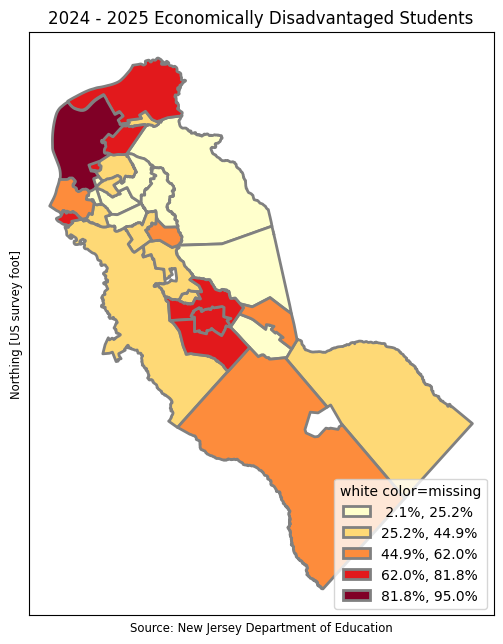

In [ ]:
# Clean and convert the column to numeric floats before plotting
# Clean and convert the 2023-2024 column to numeric floats only if it is currently text/object
if a1['Economically Disadvantaged Students'].dtype == 'object':
    a1['Economically Disadvantaged Students'] = a1['Economically Disadvantaged Students'].str.rstrip('%').astype('float')

fig, ax = plt.subplots(1, figsize=(6,10))
a1.plot(ax=ax,column='Economically Disadvantaged Students',legend=True,cmap='YlOrRd',
          scheme='natural_breaks',k=5, edgecolor='grey',linewidth=2,
          legend_kwds= {"fmt": "{:.1f}%",'loc':'lower right','markerscale':1.4})
leg1 = ax.get_legend()
if leg1 is not None:
    leg1.set_title('white color=missing')
ax.title.set_text("2024 - 2025 Economically Disadvantaged Students")
ax.set_xticks([]) #kills xticks
ax.set_yticks([]) #kills xticks
ax.set_xlabel('Source: New Jersey Department of Education')
plt.show()

In [ ]:
#For School Year 2023-2024
#Rename columns, only include 23-24 School Year, make upper case and strip white space, split Muni into first word only
DisXls2 = DisXls[DisXls['SchoolYear'] =='2023-24'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls2['DistrictName'] = DisXls2.DistrictName.str.strip()

DisXls2.rename(columns={'DistrictName' : 'District'}, inplace=True)
DisXls2['District'] = DisXls2['District'].str.upper()
DisXls2['District'] = DisXls2['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
DisXls2['District'] = DisXls2['District'].str.replace("LAWNSIDET", "LAWNSIDE")
DisXls2["District"] = DisXls2["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
DisXls2["District"] = DisXls2["District"].str.replace(" REGIONAL", "")
DisXls2["District"] = DisXls2["District"].str.replace(" SCHOOL DISTRICT", "")
DisXls2["District"] = DisXls2["District"].str.replace(" PUBLIC SCHOOLS", "")
DisXls2["District"] = DisXls2["District"].str.replace(" BOARD OF EDUCATION", "")

# Format DistrictCode as a zero-padded 4-character string (e.g., 0150)
DisXls2['DistrictCode'] = DisXls2['DistrictCode'].apply(lambda x: f"{int(x):04d}" if pd.notnull(x) else x)

DisXls2

,CountyName,DistrictCode,District,Economically Disadvantaged Students
3,Camden,0150,AUDUBON,19.7%
8,Camden,0190,BARRINGTON,35.5%
13,Camden,0260,BELLMAWR,47.4%
18,Camden,0330,BERLIN BOROUGH,17.2%
23,Camden,0340,BERLIN TOWNSHIP,36.4%
28,Camden,0390,BLACK HORSE PIKE,34.3%
33,Camden,0580,BROOKLAWN,67.3%
38,Camden,0680,CAMDEN CITY,54.7%
43,Camden,0700,CAMDEN COUNTY TECHNICAL,50.2%
48,Camden,0800,CHERRY HILL,18.1%


In [ ]:
a2 = pd.merge(cchs, DisXls2, left_on=['District'], right_on=['District'], how='outer', indicator=True)
a2.columns
a2[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry', 'type',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,3401050,AUDUBON,Camden,0150,19.7%,both
1,3401170,BARRINGTON,Camden,0190,35.5%,both
2,NaN,BELLMAWR,Camden,0260,47.4%,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,17.2%,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,36.4%,both
5,3401770,BLACK HORSE PIKE,Camden,0390,34.3%,both
6,3402370,BROOKLAWN,Camden,0580,67.3%,both
7,3402640,CAMDEN CITY,Camden,0680,54.7%,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,50.2%,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,59.5%,right_only


In [ ]:
a2._merge.value_counts()

,count
_merge,
both,26
right_only,16
left_only,2


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

Text(0.5, 173.76909082338324, 'Source: New Jersey Department of Education')

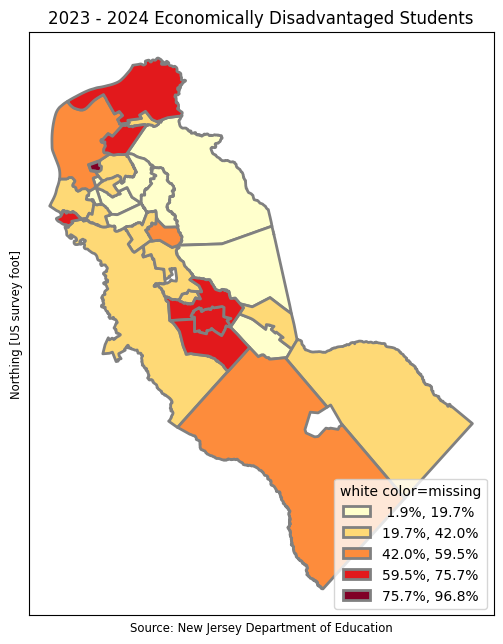

In [ ]:
# Clean and convert the 2023-2024 column to numeric floats only if it is currently text/object
if a2['Economically Disadvantaged Students'].dtype == 'object':
    a2['Economically Disadvantaged Students'] = a2['Economically Disadvantaged Students'].str.rstrip('%').astype('float')

fig, ax = plt.subplots(1, figsize=(6,10))
a2.plot(ax=ax,column='Economically Disadvantaged Students',legend=True,cmap='YlOrRd',
          scheme='natural_breaks',k=5, edgecolor='grey',linewidth=2,
          legend_kwds= {"fmt": "{:.1f}%",'loc':'lower right','markerscale':1.4})
leg1 = ax.get_legend()
if leg1 is not None:
    leg1.set_title('white color=missing')
ax.title.set_text("2023 - 2024 Economically Disadvantaged Students")
ax.set_xticks([]) #kills xticks
ax.set_yticks([]) #kills xticks
ax.set_xlabel('Source: New Jersey Department of Education')
plt.show()

In [ ]:
#For School Year 2022-2023
#Rename columns, only include 22-23 School Year, make upper case and strip white space, split Muni into first word only
DisXls3 = DisXls[DisXls['SchoolYear'] =='2022-23'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls3['DistrictName'] = DisXls3.DistrictName.str.strip()

DisXls3.rename(columns={'DistrictName' : 'District'}, inplace=True)
DisXls3['District'] = DisXls3['District'].str.upper()
DisXls3['District'] = DisXls3['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
DisXls3['District'] = DisXls3['District'].str.replace("LAWNSIDET", "LAWNSIDE")
DisXls3["District"] = DisXls3["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
DisXls3["District"] = DisXls3["District"].str.replace(" REGIONAL", "")
DisXls3["District"] = DisXls3["District"].str.replace(" SCHOOL DISTRICT", "")
DisXls3["District"] = DisXls3["District"].str.replace(" PUBLIC SCHOOLS", "")
DisXls3["District"] = DisXls3["District"].str.replace(" BOARD OF EDUCATION", "")

# Format DistrictCode as a zero-padded 4-character string (e.g., 0150)
DisXls3['DistrictCode'] = DisXls3['DistrictCode'].apply(lambda x: f"{int(x):04d}" if pd.notnull(x) else x)

DisXls3

,CountyName,DistrictCode,District,Economically Disadvantaged Students
2,Camden,0150,AUDUBON,20.3%
7,Camden,0190,BARRINGTON,25.9%
12,Camden,0260,BELLMAWR,43.9%
17,Camden,0330,BERLIN BOROUGH,11.3%
22,Camden,0340,BERLIN TOWNSHIP,41.4%
27,Camden,0390,BLACK HORSE PIKE,31.3%
32,Camden,0580,BROOKLAWN,65.0%
37,Camden,0680,CAMDEN CITY,54.5%
42,Camden,0700,CAMDEN COUNTY TECHNICAL,49.5%
47,Camden,0800,CHERRY HILL,18.8%


In [ ]:
a3 = pd.merge(cchs, DisXls3, left_on=['District'], right_on=['District'], how='outer', indicator=True)
a3.columns
a3[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry', 'type',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,3401050,AUDUBON,Camden,0150,20.3%,both
1,3401170,BARRINGTON,Camden,0190,25.9%,both
2,NaN,BELLMAWR,Camden,0260,43.9%,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,11.3%,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,41.4%,both
5,3401770,BLACK HORSE PIKE,Camden,0390,31.3%,both
6,3402370,BROOKLAWN,Camden,0580,65.0%,both
7,3402640,CAMDEN CITY,Camden,0680,54.5%,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,49.5%,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,85.6%,right_only


In [ ]:
a3._merge.value_counts()

,count
_merge,
both,26
right_only,16
left_only,2


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

Text(0.5, 173.76909082338324, 'Source: New Jersey Department of Education')

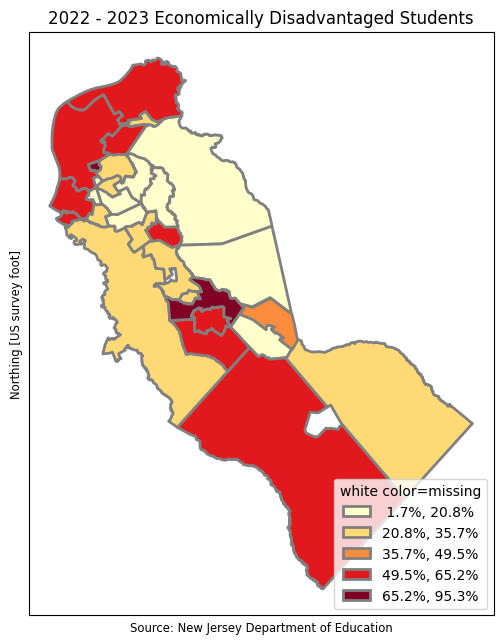

In [ ]:
# Clean and convert the 2023-2024 column to numeric floats only if it is currently text/object
if a3['Economically Disadvantaged Students'].dtype == 'object':
    a3['Economically Disadvantaged Students'] = a3['Economically Disadvantaged Students'].str.rstrip('%').astype('float')

fig, ax = plt.subplots(1, figsize=(6,10))
a3.plot(ax=ax,column='Economically Disadvantaged Students',legend=True,cmap='YlOrRd',
          scheme='natural_breaks',k=5, edgecolor='grey',linewidth=2,
          legend_kwds= {"fmt": "{:.1f}%",'loc':'lower right','markerscale':1.4})
leg1 = ax.get_legend()
if leg1 is not None:
    leg1.set_title('white color=missing')
ax.title.set_text("2022 - 2023 Economically Disadvantaged Students")
ax.set_xticks([]) #kills xticks
ax.set_yticks([]) #kills xticks
ax.set_xlabel('Source: New Jersey Department of Education')
plt.show()

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2024 - 2025 School Year')

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2023 - 2024 School Year')

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2022 - 2023 School Year')

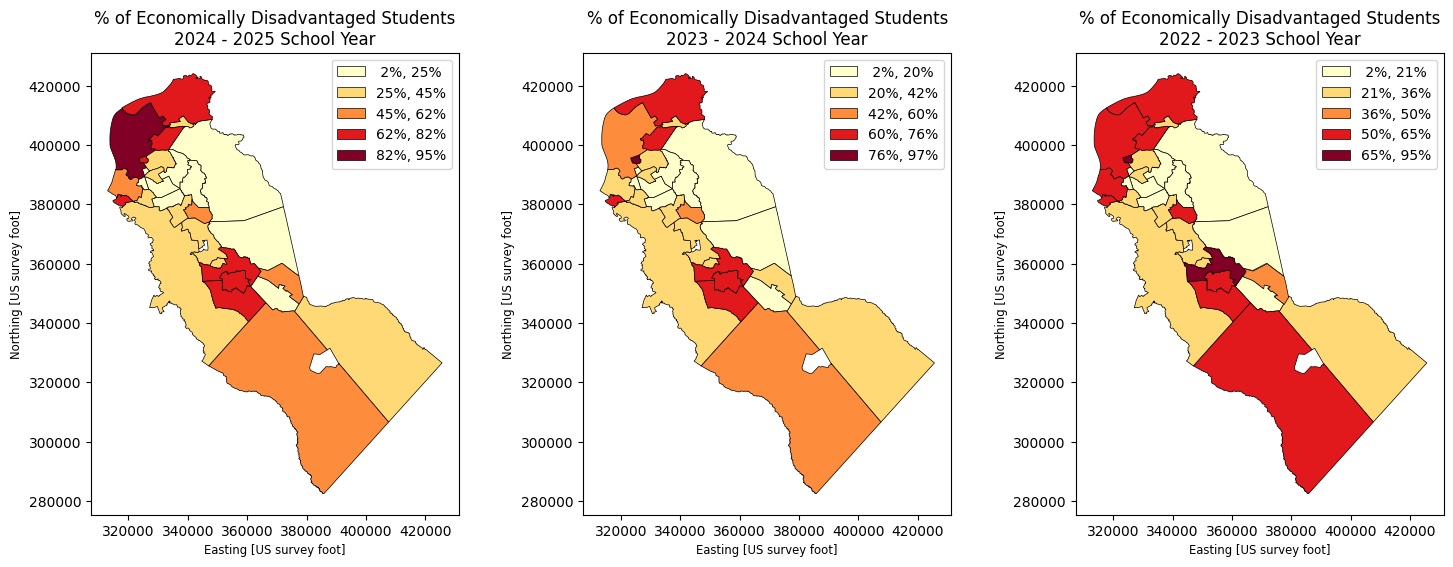

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Convert the 'Economically Disadvantaged Students' column to numeric, handling NaN values
a1['Economically Disadvantaged Students'] = a1['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a1.plot(ax=ax1, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax1.set_title('''% of Economically Disadvantaged Students\n2024 - 2025 School Year''')

# Convert the 'Economically Disadvantaged Students' column to numeric, handling NaN values
a2['Economically Disadvantaged Students'] = a2['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a2.plot(ax=ax2, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax2.set_title('''% of Economically Disadvantaged Students\n2023 - 2024 School Year''')

# Convert the 'Economically Disadvantaged Students' column to numeric, handling NaN values
a3['Economically Disadvantaged Students'] = a3['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a3.plot(ax=ax3, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax3.set_title('''% of Economically Disadvantaged Students\n2022 - 2023 School Year''')

In [ ]:
#in-school incidents involving violence, weapons, substance abuse and vandalism
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
BehXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School%20Incidents.xlsx', header = 3)

In [ ]:
##identify headings of Excel file
BehXls.head(3)

,CountyCode,CountyName,DistrictCode,DistrictName,SchoolYear,Violence,Weapons,Vandalism,Substances,HIB,TotalUniqueIncidents,IncidentsPer100Students
0,01,Atlantic,0010,Absecon Public Schools District,2024-25,1.0,0.0,0.0,0.0,5.0,6.0,0.64
1,01,Atlantic,0110,Atlantic City School District,2024-25,130.0,12.0,4.0,36.0,22.0,204.0,3.17
2,01,Atlantic,0120,Atlantic County Vocational School District,2024-25,2.0,0.0,2.0,10.0,2.0,16.0,0.89


In [ ]:
#For School Year 2024-2025
#First subset the loaded BehXls to create BehXls1 for the 24-25 School Year
BehXls1 = BehXls[BehXls['CountyName'] == 'Camden']

#Rename columns, make upper case and strip white space, split Muni into first word only
BehXls1['DistrictName'] = BehXls1.DistrictName.str.strip()

BehXls1.rename(columns={'DistrictName' : 'District'}, inplace=True)
BehXls1['District'] = BehXls1['District'].str.upper()
BehXls1['District'] = BehXls1['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
BehXls1['District'] = BehXls1['District'].str.replace("LAWNSIDET", "LAWNSIDE")
BehXls1["District"] = BehXls1["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
BehXls1["District"] = BehXls1["District"].str.replace(" REGIONAL", "")
BehXls1["District"] = BehXls1["District"].str.replace(" SCHOOL DISTRICT", "")
BehXls1["District"] = BehXls1["District"].str.replace(" PUBLIC SCHOOLS", "")
BehXls1["District"] = BehXls1["District"].str.replace(" BOARD OF EDUCATION", "")

# Format DistrictCode as a zero-padded 4-character string only if it is a digit/numeric
BehXls1['DistrictCode'] = BehXls1['DistrictCode'].apply(lambda x: f"{int(x):04d}" if pd.notnull(x) and str(x).strip().isdigit() else x)

BehXls1

/tmp/ipykernel_2604/967806819.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  BehXls1['DistrictName'] = BehXls1.DistrictName.str.strip()
/tmp/ipykernel_2604/967806819.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  BehXls1.rename(columns={'DistrictName' : 'District'}, inplace=True)
/tmp/ipykernel_2604/967806819.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide

,CountyCode,CountyName,DistrictCode,District,SchoolYear,Violence,Weapons,Vandalism,Substances,HIB,TotalUniqueIncidents,IncidentsPer100Students
139,07,Camden,0150,AUDUBON,2024-25,6.0,2.0,1.0,3.0,6.0,18.0,1.27
140,07,Camden,0190,BARRINGTON,2024-25,2.0,0.0,0.0,0.0,0.0,2.0,0.38
141,07,Camden,0260,BELLMAWR,2024-25,2.0,0.0,0.0,0.0,0.0,2.0,0.17
142,07,Camden,0330,BERLIN BOROUGH,2024-25,14.0,0.0,0.0,0.0,4.0,18.0,1.99
143,07,Camden,0340,BERLIN TOWNSHIP,2024-25,6.0,1.0,0.0,0.0,5.0,12.0,1.94
144,07,Camden,0390,BLACK HORSE PIKE,2024-25,50.0,3.0,6.0,41.0,15.0,114.0,3.35
145,07,Camden,0580,BROOKLAWN,2024-25,4.0,0.0,0.0,1.0,0.0,5.0,1.72
146,07,Camden,0680,CAMDEN CITY,2024-25,194.0,8.0,27.0,51.0,24.0,297.0,4.33
147,07,Camden,0700,CAMDEN COUNTY TECHNICAL,2024-25,17.0,5.0,3.0,28.0,7.0,60.0,2.80
148,07,Camden,0800,CHERRY HILL,2024-25,21.0,6.0,5.0,82.0,63.0,175.0,1.62


In [ ]:
a4 = pd.merge(cchs, BehXls1, left_on=['District'], right_on=['District'], how='outer', indicator=True)
a4.columns
a4[['GEOID','District','CountyName', 'DistrictCode_y', 'IncidentsPer100Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode_x', 'District', 'GEOID', 'geometry',
       'type', 'CountyCode_y', 'CountyName', 'DistrictCode_y', 'SchoolYear',
       'Violence', 'Weapons', 'Vandalism', 'Substances', 'HIB',
       'TotalUniqueIncidents', 'IncidentsPer100Students', '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,IncidentsPer100Students,_merge
0,3401050,AUDUBON,Camden,0150,1.27,both
1,3401170,BARRINGTON,Camden,0190,0.38,both
2,NaN,BELLMAWR,Camden,0260,0.17,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,1.99,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,1.94,both
5,3401770,BLACK HORSE PIKE,Camden,0390,3.35,both
6,3402370,BROOKLAWN,Camden,0580,1.72,both
7,3402640,CAMDEN CITY,Camden,0680,4.33,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,2.80,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,5.34,right_only


In [ ]:
a4._merge.value_counts()

,count
_merge,
both,26
right_only,16
left_only,2


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

Text(0.5, 173.76909082338324, 'Source: New Jersey Department of Education')

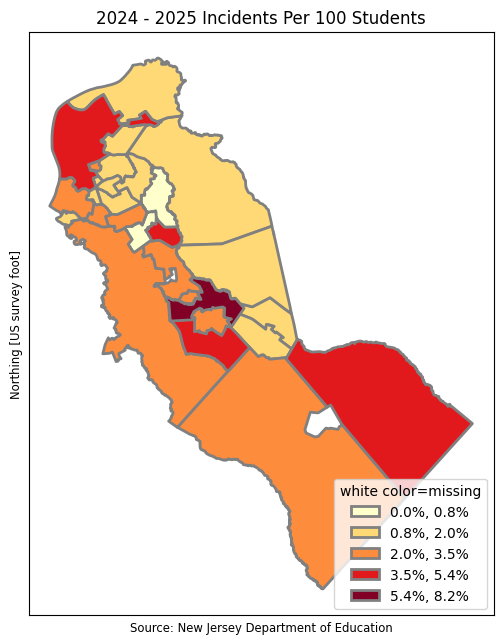

In [ ]:
# Clean and convert the 2023-2024 column to numeric floats only if it is currently text/object
if a4['IncidentsPer100Students'].dtype == 'object':
    a4['IncidentsPer100Students'] = a4['IncidentsPer100Students'].str.rstrip('%').astype('float')

fig, ax = plt.subplots(1, figsize=(6,10))
a4.plot(ax=ax,column='IncidentsPer100Students',legend=True,cmap='YlOrRd',
          scheme='natural_breaks',k=5, edgecolor='grey',linewidth=2,
          legend_kwds= {"fmt": "{:.1f}%",'loc':'lower right','markerscale':1.4})
leg1 = ax.get_legend()
if leg1 is not None:
    leg1.set_title('white color=missing')
ax.title.set_text("2024 - 2025 Incidents Per 100 Students")
ax.set_xticks([]) #kills xticks
ax.set_yticks([]) #kills xticks
ax.set_xlabel('Source: New Jersey Department of Education')
plt.show()

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2024 - 2025 School Year')

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Incidents Per 100 Students\n2024 - 2025 School Year')

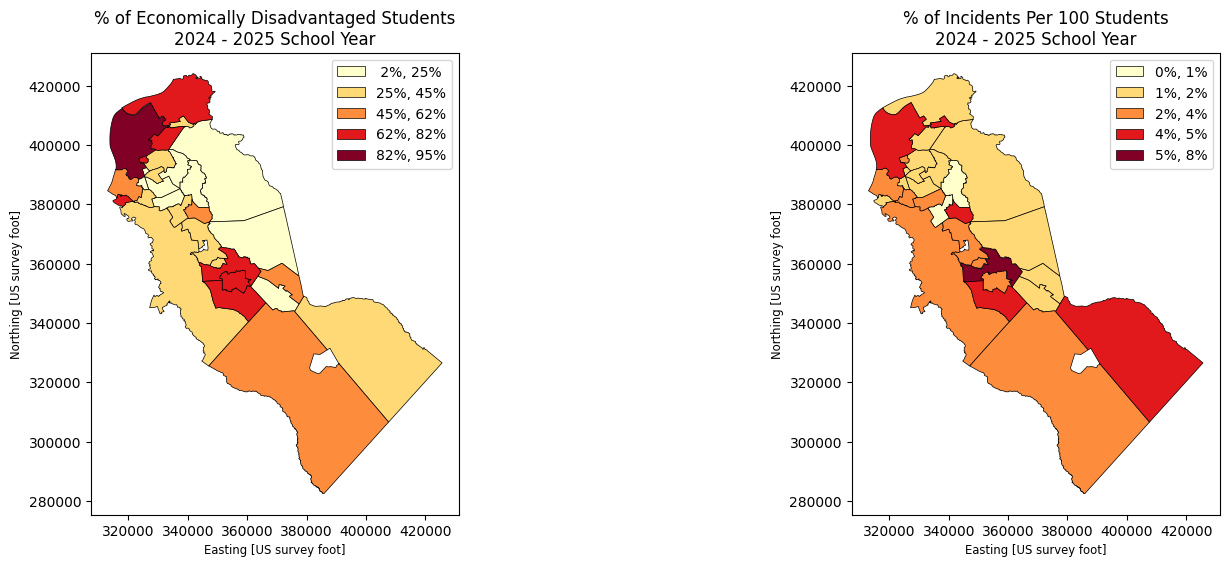

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Convert the 'Economically Disadvantaged Students' column to numeric, handling NaN values
a1['Economically Disadvantaged Students'] = a1['Economically Disadvantaged Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a1.plot(ax=ax1, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax1.set_title('''% of Economically Disadvantaged Students\n2024 - 2025 School Year''')

# Convert the 'IncidentsPer100Students' column to numeric, handling NaN values
a4['IncidentsPer100Students'] = a4['IncidentsPer100Students'].apply(lambda x: float(x.replace('%', '')) if isinstance(x, str) else x)

a4.plot(ax=ax2, column='IncidentsPer100Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax2.set_title('''% of Incidents Per 100 Students\n2024 - 2025 School Year''')

In [ ]:
#in-school incidents involving violence, weapons, substance abuse and vandalism
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
AbsXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Chronic%20Absenteeism%20by%20Grade.xlsx', header = 3)

In [ ]:
AbsXls.head(3)

,CountyCode,CountyName,DistrictCode,DistrictName,SchoolYear,Grade,ChronicAbsenteeismRate_District,ChronicAbsenteeismRate_State
0,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 1,18.7%,14.3%
1,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 2,6.9%,12.7%
2,01,Atlantic,0010,Absecon Public Schools District,2024-25,Grade 3,12.7%,11.6%


In [ ]:
#For School Year 2024-2025
#First subset the loaded AbsXls to create AbsXls1 for Camden county
AbsXls1 = AbsXls[AbsXls['CountyCode'] == '07']

# Filter to keep only Grades 9, 10, 11, and 12 using .isin()
AbsXls1 = AbsXls1[AbsXls1['Grade'].isin(['Grade 9', 'Grade 10', 'Grade 11', 'Grade 12'])]

#Rename columns, make upper case and strip white space, split Muni into first word only
AbsXls1['DistrictName'] = AbsXls1.DistrictName.str.strip()

AbsXls1.rename(columns={'DistrictName' : 'District'}, inplace=True)
AbsXls1['District'] = AbsXls1['District'].str.upper()
AbsXls1['District'] = AbsXls1['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
AbsXls1['District'] = AbsXls1['District'].str.replace("LAWNSIDET", "LAWNSIDE")
AbsXls1["District"] = AbsXls1["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
AbsXls1["District"] = AbsXls1["District"].str.replace(" REGIONAL", "")
AbsXls1["District"] = AbsXls1["District"].str.replace(" SCHOOL DISTRICT", "")
AbsXls1["District"] = AbsXls1["District"].str.replace(" PUBLIC SCHOOLS", "")
AbsXls1["District"] = AbsXls1["District"].str.replace(" BOARD OF EDUCATION", "")

# Format DistrictCode as a zero-padded 4-character string only if it is a digit/numeric
AbsXls1['DistrictCode'] = AbsXls1['DistrictCode'].apply(lambda x: f"{int(x):04d}" if pd.notnull(x) and str(x).strip().isdigit() else x)

# Clean and convert the ChronicAbsenteeismRate_District column to numeric floats before computing the mean
if AbsXls1['ChronicAbsenteeismRate_District'].dtype == 'object':
    AbsXls1['ChronicAbsenteeismRate_District'] = AbsXls1['ChronicAbsenteeismRate_District'].str.rstrip('%').astype('float')

# 4. Group grades together as 1 average rate per district
AbsXls1 = AbsXls1.groupby(['DistrictCode', 'District'], as_index=False)['ChronicAbsenteeismRate_District'].mean()
AbsXls1

,DistrictCode,District,ChronicAbsenteeismRate_District
0,0150,AUDUBON,12.250
1,0390,BLACK HORSE PIKE,6.625
2,0680,CAMDEN CITY,56.675
3,0700,CAMDEN COUNTY TECHNICAL,9.800
4,0800,CHERRY HILL,16.875
5,0940,COLLINGSWOOD,17.250
6,1255,EASTERN CAMDEN COUNTY,16.425
7,1770,GLOUCESTER CITY,22.825
8,1799,"KIPP: COOPER NORCROSS, A NEW JERSEY NONPROFIT ...",62.100
9,1801,"CAMDEN PREP, INC.",69.000


In [ ]:
a5 = pd.merge(cchs, AbsXls1, left_on=['District'], right_on=['District'], how='outer', indicator=True)
a5.columns
a5[['GEOID','District', 'DistrictCode_y', 'ChronicAbsenteeismRate_District', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry', 'type',
       'DistrictCode_y', 'ChronicAbsenteeismRate_District', '_merge'],
      dtype='object')

,GEOID,District,DistrictCode_y,ChronicAbsenteeismRate_District,_merge
0,3401050,AUDUBON,0150,12.250,both
1,3401170,BARRINGTON,NaN,NaN,left_only
2,3401620,BERLIN TOWNSHIP,NaN,NaN,left_only
3,3401770,BLACK HORSE PIKE,0390,6.625,both
4,3402370,BROOKLAWN,NaN,NaN,left_only
5,3402640,CAMDEN CITY,0680,56.675,both
6,NaN,CAMDEN COUNTY TECHNICAL,0700,9.800,right_only
7,NaN,"CAMDEN PREP, INC.",1801,69.000,right_only
8,3403000,CHERRY HILL,0800,16.875,both
9,3403030,CHESILHURST,NaN,NaN,left_only


In [ ]:
a5._merge.value_counts()

,count
_merge,
both,15
left_only,13
right_only,4


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

[]

[]

Text(0.5, 80.7222222222222, 'Source: New Jersey Department of Education')

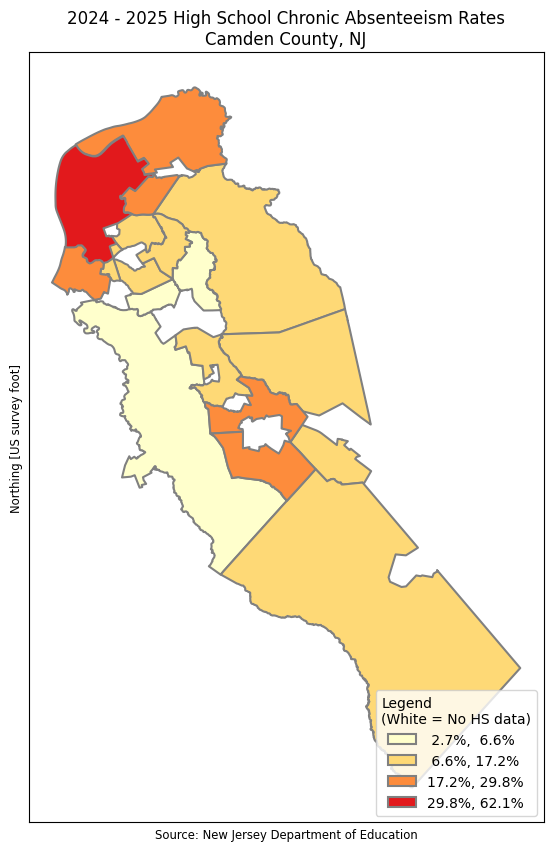

In [ ]:
# Map the 2024 - 2025 High School Chronic Absenteeism Rates
import matplotlib.pyplot as plt

# Ensure clean floating-point values for mapping
if a5['ChronicAbsenteeismRate_District'].dtype == 'object':
    a5['ChronicAbsenteeismRate_District'] = a5['ChronicAbsenteeismRate_District'].str.rstrip('%').astype('float')

fig, ax = plt.subplots(1, figsize=(8, 10))
a5.plot(
    ax=ax,
    column='ChronicAbsenteeismRate_District',
    legend=True,
    cmap='YlOrRd',
    scheme='natural_breaks',
    k=5,
    edgecolor='grey',
    linewidth=1.5,
    legend_kwds={'fmt': '{:.1f}%', 'loc': 'lower right', 'title': 'Absenteeism Rate'}
)

# Handle missing high school data values dynamically
leg = ax.get_legend()
if leg is not None:
    leg.set_title('Legend\n(White = No HS data)')

ax.title.set_text("2024 - 2025 High School Chronic Absenteeism Rates\nCamden County, NJ")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Source: New Jersey Department of Education')
plt.show()

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(384613.2010315965, 314669.1400799006, 'WINSLOW TOWNSHIP')

Text(331290.2186003814, 386149.17838593945, 'AUDUBON')

Text(331080.1053885005, 394624.48738672957, 'COLLINGSWOOD')

...

Text(338350.7351210454, 353271.08649789914, 'BLACK HORSE PIKE')

Text(362431.0925513975, 367542.9099883139, 'EASTERN CAMDEN COUNTY')

Text(0.5, 1.0, '% of Economically Disadvantaged Students\nwith Chronic Absenteeism Rates (Blue Dots)')

[]

[]

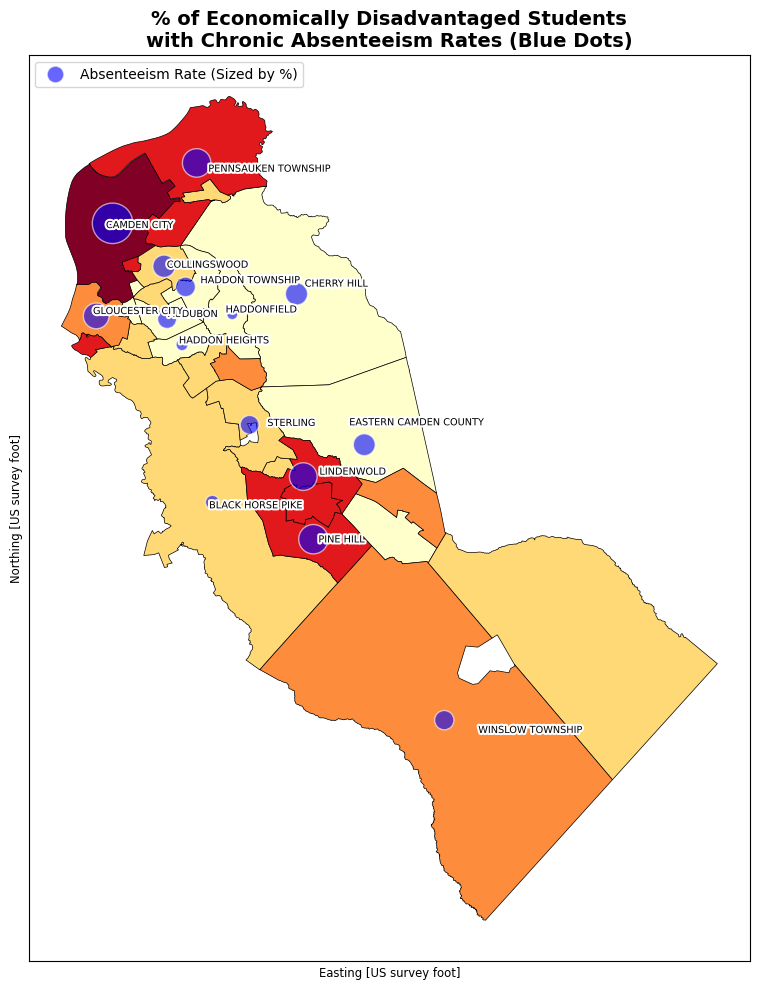

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patheffects import withStroke

# 1. Clean data and merge with district boundaries to define abs_geo
AbsXls1_clean = AbsXls1.copy()
if AbsXls1_clean['ChronicAbsenteeismRate_District'].dtype == object:
    AbsXls1_clean['ChronicAbsenteeismRate_District'] = pd.to_numeric(
        AbsXls1_clean['ChronicAbsenteeismRate_District'].astype(str).str.replace('%', '').str.strip(),
        errors='coerce'
    )

# Merge based on 'District' which is present in both cchs and AbsXls1_clean
abs_geo = gpd.GeoDataFrame(pd.merge(cchs, AbsXls1_clean, on='District', how='inner'), crs=cchs.crs)

# Ensure background dataset has numeric values
a1_gpd = a1.copy()
if a1_gpd['Economically Disadvantaged Students'].dtype == object:
    a1_gpd['Economically Disadvantaged Students'] = pd.to_numeric(
        a1_gpd['Economically Disadvantaged Students'].astype(str).str.replace('%', '').str.strip(),
        errors='coerce'
    )

# Convert to GeoDataFrame
a1_gpd = gpd.GeoDataFrame(a1_gpd, geometry='geometry', crs=cchs.crs)

# 2. Compute centroids for the absenteeism dots
abs_geo['centroid'] = abs_geo.geometry.centroid
abs_centroids = abs_geo.set_geometry('centroid')

# 3. Create the single-panel overlay map
fig, ax = plt.subplots(1, figsize=(14, 10))

# Plot background: Economically Disadvantaged Students
a1_gpd.plot(
    ax=ax,
    column='Economically Disadvantaged Students',
    legend=True,
    cmap='YlOrRd',
    scheme='natural_breaks',
    k=5,
    edgecolor='black',
    linewidth=.5,
    legend_kwds={"fmt": "{:.0f}%", "loc": "lower right", "title": "Eco. Disadvantaged %"}
)

# Plot overlay: Chronic Absenteeism as sized blue dots at the district centroids
abs_centroids.plot(
    ax=ax,
    color='blue',
    markersize=abs_centroids['ChronicAbsenteeismRate_District'] * 15,
    alpha=0.6,
    edgecolor='white',
    linewidth=1
)

# Plot district labels dynamically using names from 'abs_geo'
for _, row in abs_geo.iterrows():
    rep_point = row.geometry.representative_point()
    label_text = row['District']
    if pd.notna(label_text):
        ax.annotate(
            text=label_text,
            xy=(rep_point.x, rep_point.y),
            horizontalalignment='left',
            fontsize=7,
            color='black',
            path_effects=[withStroke(linewidth=3, foreground='white')]
        )

# Titles & Legend configurations
ax.set_title('% of Economically Disadvantaged Students\nwith Chronic Absenteeism Rates (Blue Dots)', fontsize=14, fontweight='bold')
ax.set_xticks([]); ax.set_yticks([])

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Absenteeism Rate (Sized by %)',
           markerfacecolor='blue', markersize=12, alpha=0.6, markeredgecolor='white')
]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\nwith Chronic Absenteeism Rates (Blue Dots)')

[]

[]

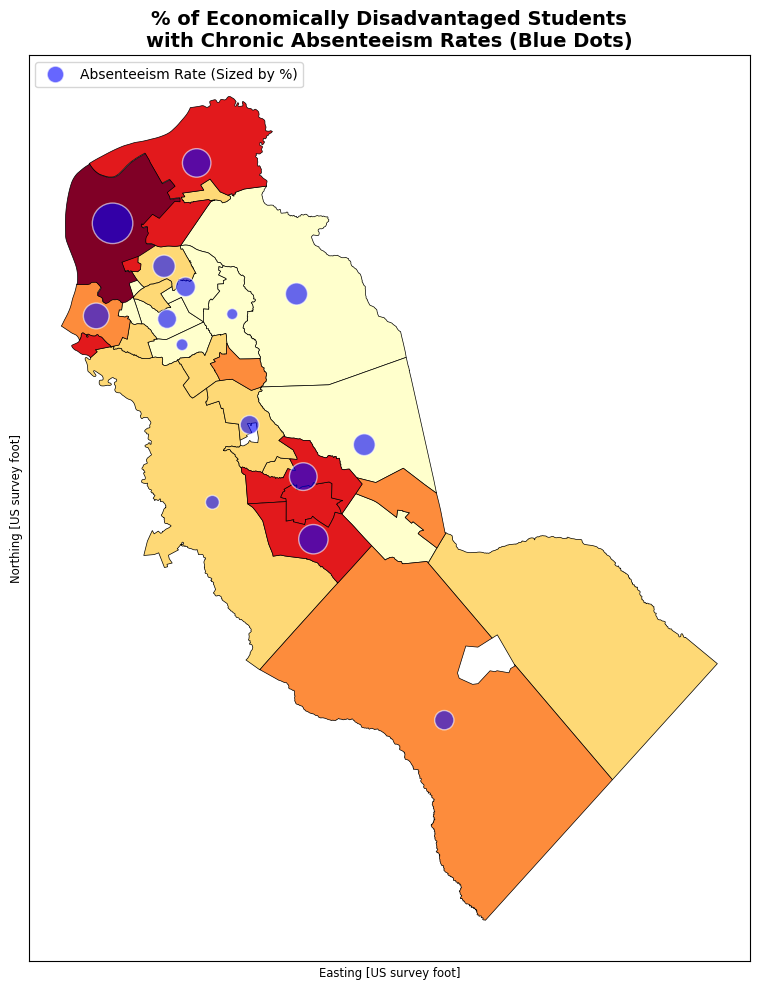

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patheffects import withStroke

# 1. Clean data and merge with district boundaries to define abs_geo
AbsXls1_clean = AbsXls1.copy()
if AbsXls1_clean['ChronicAbsenteeismRate_District'].dtype == object:
    AbsXls1_clean['ChronicAbsenteeismRate_District'] = pd.to_numeric(
        AbsXls1_clean['ChronicAbsenteeismRate_District'].astype(str).str.replace('%', '').str.strip(),
        errors='coerce'
    )

# Merge based on 'District' which is present in both cchs and AbsXls1_clean
abs_geo = gpd.GeoDataFrame(pd.merge(cchs, AbsXls1_clean, on='District', how='inner'), crs=cchs.crs)

# Ensure background dataset has numeric values
a1_gpd = a1.copy()
if a1_gpd['Economically Disadvantaged Students'].dtype == object:
    a1_gpd['Economically Disadvantaged Students'] = pd.to_numeric(
        a1_gpd['Economically Disadvantaged Students'].astype(str).str.replace('%', '').str.strip(),
        errors='coerce'
    )

# Convert to GeoDataFrame
a1_gpd = gpd.GeoDataFrame(a1_gpd, geometry='geometry', crs=cchs.crs)

# 2. Compute centroids for the absenteeism dots
abs_geo['centroid'] = abs_geo.geometry.centroid
abs_centroids = abs_geo.set_geometry('centroid')

# 3. Create the single-panel overlay map
fig, ax = plt.subplots(1, figsize=(14, 10))

# Plot background: Economically Disadvantaged Students
a1_gpd.plot(
    ax=ax,
    column='Economically Disadvantaged Students',
    legend=True,
    cmap='YlOrRd',
    scheme='natural_breaks',
    k=5,
    edgecolor='black',
    linewidth=.5,
    legend_kwds={"fmt": "{:.0f}%", "loc": "lower right", "title": "Eco. Disadvantaged %"}
)

# Plot overlay: Chronic Absenteeism as sized blue dots at the district centroids
abs_centroids.plot(
    ax=ax,
    color='Blue',
    markersize=abs_centroids['ChronicAbsenteeismRate_District'] * 15,
    alpha=0.6,
    edgecolor='white',
    linewidth=1
)

# Titles & Legend configurations
ax.set_title('% of Economically Disadvantaged Students\nwith Chronic Absenteeism Rates (Blue Dots)', fontsize=14, fontweight='bold')
ax.set_xticks([]); ax.set_yticks([])

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Absenteeism Rate (Sized by %)',
           markerfacecolor='blue', markersize=12, alpha=0.6, markeredgecolor='white')
]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()